# Artificial Intelligence

* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr


## Association Rule Mining with Apriori
### Unsupervised Learning

**Goal:** Discover products that frequently occur together in supermarket transactions.

1. Download an online grocery transaction dataset.
2. Convert transactions into a one-hot encoded table.
3. Find frequent itemsets with the Apriori algorithm.
4. Generate and interpret association rules using support, confidence, and lift.
5. Visualize the results.

**Important:** Association rules reveal co-occurrence patterns. They do not demonstrate that purchasing one product causes the purchase of another.

## 1. Install the required libraries

In [11]:
%pip -q install pandas matplotlib mlxtend requests

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [3]:
import csv
import io
import requests
import pandas as pd
import matplotlib.pyplot as plt

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

pd.set_option("display.max_colwidth", 100)

## 3. Download the online dataset

The dataset contains supermarket transactions. Each row represents one shopping basket, and the products in that row were purchased together.

The code checks the download response before parsing the file.

In [12]:
url = "https://raw.githubusercontent.com/SavioSal/datasets/master/store_data_association_rules.csv"

response = requests.get(url, timeout=30)
response.raise_for_status()

transactions = [
    [item.strip() for item in row if item.strip()]
    for row in csv.reader(io.StringIO(response.text))]

# Remove empty transactions
transactions = [row for row in transactions if row]

print("Number of transactions:", len(transactions))
print("First five transactions:")
for transaction in transactions[:5]:
    print(transaction)

Number of transactions: 7501
First five transactions:
['shrimp', 'almonds', 'avocado', 'vegetables mix', 'green grapes', 'whole weat flour', 'yams', 'cottage cheese', 'energy drink', 'tomato juice', 'low fat yogurt', 'green tea', 'honey', 'salad', 'mineral water', 'salmon', 'antioxydant juice', 'frozen smoothie', 'spinach', 'olive oil']
['burgers', 'meatballs', 'eggs']
['chutney']
['turkey', 'avocado']
['mineral water', 'milk', 'energy bar', 'whole wheat rice', 'green tea']


## 4. Convert transactions into a one-hot encoded table

Apriori expects a table in which each column represents a product. `True` indicates that the product appears in that transaction; `False` indicates that it does not.

In [13]:
encoder = TransactionEncoder()
encoded_array = encoder.fit(transactions).transform(transactions)

basket = pd.DataFrame(encoded_array, columns=encoder.columns_)

print("Dataset shape:", basket.shape)
display(basket.head())

Dataset shape: (7501, 119)


,almonds,antioxydant juice,asparagus,avocado,babies food,bacon,barbecue sauce,black tea,blueberries,body spray,...,turkey,vegetables mix,water spray,white wine,whole weat flour,whole wheat pasta,whole wheat rice,yams,yogurt cake,zucchini
0,True,True,False,True,False,False,False,False,False,False,...,False,True,False,False,True,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,True,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False


## 5. Find frequent itemsets with Apriori

`min_support=0.01` means that an itemset must appear in at least 1% of all transactions to be retained. Try changing this threshold and observe how the results change.

In [15]:
frequent_itemsets = apriori(
    basket,
    min_support=0.01,
    use_colnames=True)

frequent_itemsets = frequent_itemsets.sort_values(
    "support", ascending=False
).reset_index(drop=True)

print("Number of frequent itemsets:", len(frequent_itemsets))
display(frequent_itemsets.head(15))

Number of frequent itemsets: 257


,support,itemsets
0,0.238368,(mineral water)
1,0.179709,(eggs)
2,0.174110,(spaghetti)
3,0.170911,(french fries)
4,0.163845,(chocolate)
5,0.132116,(green tea)
6,0.129583,(milk)
7,0.098254,(ground beef)
8,0.095321,(frozen vegetables)
9,0.095054,(pancakes)


## 6. Generate association rules

We use a minimum confidence of 0.20. A rule such as `{bread} → {milk}` means that the algorithm found a pattern in which milk often appears in transactions that contain bread.

In [16]:
if frequent_itemsets.empty:
    raise ValueError("No frequent itemsets found. Try lowering min_support.")

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.20
)

if rules.empty:
    print("No rules met the confidence threshold. Try lowering min_threshold.")
else:
    rules = rules.sort_values("lift", ascending=False).reset_index(drop=True)

    display(
        rules[[
            "antecedents", "consequents",
            "support", "confidence", "lift"
        ]].head(15)
    )

,antecedents,consequents,support,confidence,lift
0,(herb & pepper),(ground beef),0.015998,0.323450,3.291994
1,"(mineral water, spaghetti)",(ground beef),0.017064,0.285714,2.907928
2,(tomatoes),(frozen vegetables),0.016131,0.235867,2.474464
3,(shrimp),(frozen vegetables),0.016664,0.233209,2.446574
4,"(milk, mineral water)",(frozen vegetables),0.011065,0.230556,2.418737
5,"(ground beef, mineral water)",(spaghetti),0.017064,0.416938,2.394681
6,"(frozen vegetables, mineral water)",(milk),0.011065,0.309701,2.389991
7,"(milk, mineral water)",(ground beef),0.011065,0.230556,2.346536
8,(soup),(milk),0.015198,0.300792,2.321232
9,(spaghetti),(ground beef),0.039195,0.225115,2.291162


## 7. Interpret the three main metrics

- **Support:** The proportion of all transactions that contain both sides of the rule.
- **Confidence:** Among transactions containing the antecedent, the proportion that also contain the consequent.
- **Lift:** The confidence of the rule divided by the overall support of the consequent.

**Lift interpretation**
- `Lift > 1`: The consequent occurs more often with the antecedent than expected under independence.
- `Lift = 1`: The two sides are independent in this dataset.
- `Lift < 1`: The consequent occurs less often with the antecedent than expected under independence.

## 8. Visualize the association rules

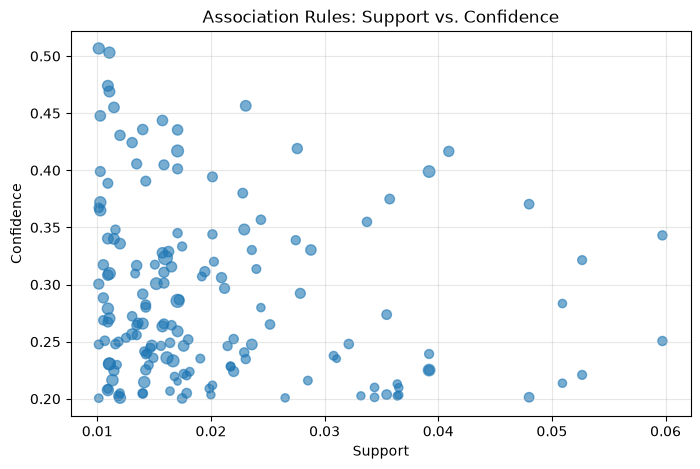

In [17]:
if not rules.empty:
    plt.figure(figsize=(8, 5))
    plt.scatter(
        rules["support"],
        rules["confidence"],
        s=rules["lift"].clip(lower=0.1) * 30,
        alpha=0.6
    )
    plt.xlabel("Support")
    plt.ylabel("Confidence")
    plt.title("Association Rules: Support vs. Confidence")
    plt.grid(alpha=0.3)
    plt.show()
else:
    print("There are no rules to visualize.")

## 9. Display the strongest rules in plain language

The following code prints the ten rules with the highest lift. A high lift can indicate an interesting association, but check support as well: a rule based on very few transactions may be unreliable.

In [18]:
if not rules.empty:
    for _, rule in rules.head(10).iterrows():
        left = ", ".join(sorted(rule["antecedents"]))
        right = ", ".join(sorted(rule["consequents"]))

        print(f"IF a transaction contains [{left}]")
        print(f"THEN it is also associated with [{right}]")
        print(f"Support:    {rule['support']:.3f}")
        print(f"Confidence: {rule['confidence']:.3f}")
        print(f"Lift:       {rule['lift']:.3f}")
        print("-" * 55)

IF a transaction contains [herb & pepper]
THEN it is also associated with [ground beef]
Support:    0.016
Confidence: 0.323
Lift:       3.292
-------------------------------------------------------
IF a transaction contains [mineral water, spaghetti]
THEN it is also associated with [ground beef]
Support:    0.017
Confidence: 0.286
Lift:       2.908
-------------------------------------------------------
IF a transaction contains [tomatoes]
THEN it is also associated with [frozen vegetables]
Support:    0.016
Confidence: 0.236
Lift:       2.474
-------------------------------------------------------
IF a transaction contains [shrimp]
THEN it is also associated with [frozen vegetables]
Support:    0.017
Confidence: 0.233
Lift:       2.447
-------------------------------------------------------
IF a transaction contains [milk, mineral water]
THEN it is also associated with [frozen vegetables]
Support:    0.011
Confidence: 0.231
Lift:       2.419
-------------------------------------------